In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import Parsers as P, Optics as O
from mppi.Utilities import Constants as Const
from mppi.Utilities import Utils
import matplotlib.pyplot as plt
import numpy as np
import os, re

# Transient absorption from the non-linear $\chi$ and comparison with the RT runs

Reconstruction of the pump induced change $\delta\chi^{neq}$ of the probe response from the equilibrium non-linear
susceptibilities extracted in `NL-Chi_Analysis.ipynb`, and comparison with the direct real-time pump-probe simulations of
D. Sangalli (kx16, one run for each pump-probe delay, in `Davide_data/`).

Structure: the RT pump-probe simulations of D. Sangalli (IP runs: reading, spectra vs the delay, 2D maps), the equilibrium
susceptibilities from `yambo_nl`, the theory and the reconstruction of $\delta\chi^{neq}$.

The formula for $\delta\chi^{neq}$ (third order terms only), its implementation (`dchi_neq`) and the approximations
are described in the last section.

The susceptibilities are taken from the kx16 runs with damping 0.3 eV (the grid of the RT runs): sine (probe only) and
P&p (pump 1e6 kW/m$^2$), 155 probe frequencies 10.000-24.919 eV with step $\omega_P/16$, so the shifted grids
$\omega\pm 2\omega_P$ fall exactly on the probe grid.

## RT pump-probe simulations of D. Sangalli (kx16, IP)

Folder `Davide_data/20250312_Report_simulations_data_kx16_ball`, runs `td-ip-ber_..._1-15b_...`: independent particles,
bands 1-15, Berry phase coupling, yambo 5.3, CRANKNIC with time step 3 as, 40 fs, no dephasing. One run for each probe
time $t_p$ (folder `delta<t_p>fs`): DELTA probe along x at $t_p$ and QSFIELD pump (phase 90°, `5SIGMA`) at 1.56 eV along
x, 6e9 kW/cm$^2$, $\sigma$ = 3.219 fs (FWHM of the envelope 7.58 fs). The file `o-abs_0-50eV_sm0.6eV.YPP-eps_along_E`
contains $\epsilon(\omega)$ computed by `ypp` from the polarization after the probe (columns: energy, Im $\epsilon$
x, y, z, Re $\epsilon$ x, y, z), 0-50 eV, step 0.01 eV, Lorentzian smoothing 0.6 eV. The folder also contains the runs
with the electron-hole interaction (`td-hsex-cv-ber`, bands 3-12), not used here.

Conventions of the plotting script of D. Sangalli (`20250312_Report_simulations_data_kx16.py`), used here:

- delay $\tau = t_p - t_P$ with the pump maximum at $t_P$ = 15.9 fs (yambo puts the center of the envelope at
  $t_{start} + (\pi/\omega_P)\,\mathrm{nint}(5\sigma\omega_P/\pi)$ = 15.909 fs; $t_p$ is read from the header);
- the reference ("Eq.") is the run with the earliest probe ($t_p$ = 5.25 fs, $\tau$ = -10.66 fs, $3.3\sigma$ before the
  pump maximum), and the changes are $\Delta X(\omega,\tau) = X(\omega,\tau) - X(\omega,\tau_{ref})$;
- reflectivity: Fresnel formula of the semi-infinite crystal, angle of incidence $\theta$ from the normal ($\theta$ =
  72° and s polarization in the figures).

In his maps the curve "Neq." of the left panel and the right panel are averages over the delays within 2 fs from
$\tau$ = 0.1 fs, and the left panel shows $-X$ (axis from -1 to 0); here they are taken at a single delay.

In [3]:
import glob
from matplotlib.colors import TwoSlopeNorm

rt_path = 'Davide_data/20250312_Report_simulations_data_kx16_ball'
rt_file = 'o-abs_0-50eV_sm0.6eV.YPP-eps_along_E'

def field_params(fname):
    # (initial time (fs), width (fs), frequency (eV), intensity (kW/cm^2)) of the fields in the header of a ypp file:
    # probe, pump
    hdr = [l for l in open(fname) if l.startswith('#')]
    get = lambda key : [float(l.split(':')[1].split()[0]) for l in hdr if '[FIELDs] '+key in l]
    return list(zip(get('Initial time'),get('Width'),get('Frequency range'),get('Intensity')))

def load_rt_runs(prefix='td-ip-ber', path=rt_path):
    # eps along x for all the probe times of a set of RT runs, sorted by the delay tau = t_p - t_P (fs)
    folders = glob.glob(os.path.join(path,prefix+'*delta*fs*'))
    t_p = np.array([field_params(os.path.join(f,rt_file))[0][0] for f in folders])
    (t_start,sigma,w_P,I_P) = field_params(os.path.join(folders[0],rt_file))[1]
    w = w_P/Const.Planck_reduced_ev_fs                                # rad/fs
    t_P = t_start + np.pi/w*np.rint(w/np.pi*5*sigma)                  # center of the QSFIELD envelope (5SIGMA)
    data = [np.loadtxt(os.path.join(folders[i],rt_file)) for i in np.argsort(t_p)]
    return dict(energy=data[0][:,0], eps=np.array([d[:,4]+1j*d[:,1] for d in data]), tau=np.sort(t_p)-t_P, t_P=t_P,
                pump=dict(freq=w_P,sigma=sigma,intensity=I_P))

def reflectivity(eps, theta=72., pol='s'):
    # Fresnel reflectivity, angle of incidence theta (degrees from the normal)
    c, q = np.cos(np.radians(theta)), np.sqrt(eps - np.sin(np.radians(theta))**2 + 0j)
    r = (c-q)/(c+q) if pol == 's' else (eps*c-q)/(eps*c+q)
    return np.abs(r)**2

def rt_quantity(runs, quantity='Im eps', change=False, relative=False, **kw):
    # Im eps, Re eps or R (n_delays, n_energies), or their change w.r.t. the reference (earliest delay)
    q = {'Im eps':lambda e : e.imag, 'Re eps':lambda e : e.real, 'R':lambda e : reflectivity(e,**kw)}[quantity](runs['eps'])
    if not change: return q
    return (q-q[0])/q[0] if relative else q-q[0]

rt_ip = load_rt_runs()
d = rt_quantity(rt_ip,change=True)
sel = (rt_ip['energy'] > 10) & (rt_ip['energy'] < 30)
print('%d delays, tau %.2f..%.2f fs (t_P = %.3f fs), E %.1f-%.1f eV, pump %s'%(len(rt_ip['tau']),rt_ip['tau'][0],
      rt_ip['tau'][-1],rt_ip['t_P'],rt_ip['energy'][0],rt_ip['energy'][-1],rt_ip['pump']))
print('delays:',np.round(rt_ip['tau'],2))
print('max |Delta Im eps| in 10-30 eV: %.1e (all the delays), %.1e at the last delay (after the pump)'%(
      np.abs(d[:,sel]).max(),np.abs(d[-1,sel]).max()))

62 delays, tau -10.66..8.09 fs (t_P = 15.909 fs), E 0.0-50.0 eV, pump {'freq': 1.56, 'sigma': 3.21892962, 'intensity': 6000000000.0}
delays: [-10.66  -7.16  -6.91  -6.66  -6.41  -6.16  -5.91  -5.66  -5.41  -4.91
  -4.66  -4.41  -4.16  -3.91  -3.66  -3.41  -3.16  -2.91  -2.66  -2.41
  -2.16  -1.91  -1.66  -1.41  -1.16  -0.91  -0.66  -0.41  -0.16   0.09
   0.34   0.59   0.84   1.09   1.34   1.59   1.84   2.09   2.34   2.59
   2.84   3.09   3.34   3.59   3.84   4.09   4.34   4.59   4.84   5.09
   5.34   5.59   5.84   6.09   6.34   6.59   6.84   7.09   7.34   7.59
   7.84   8.09]
max |Delta Im eps| in 10-30 eV: 1.8e-01 (all the delays), 8.7e-04 at the last delay (after the pump)


Spectra at selected delays (the nearest available ones): Im $\epsilon$ and its change w.r.t. the reference.

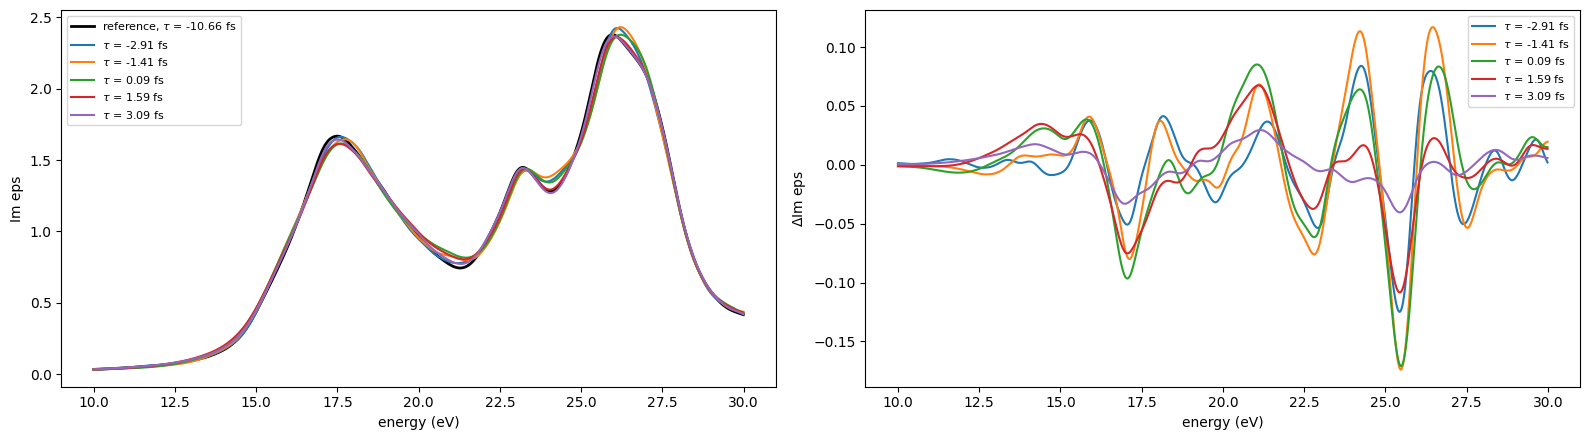

In [4]:
def plot_rt_spectra(runs, taus, quantity='Im eps', change=False, erange=(10,30), ax=None, **kw):
    # spectra (or their changes) at the delays closest to taus (fs)
    if ax is None: ax = plt.subplots(figsize=(10,4.5))[1]
    q = rt_quantity(runs,quantity,change=change,**kw)
    E = runs['energy']
    s = (E >= erange[0]) & (E <= erange[1])
    if not change: ax.plot(E[s],q[0,s],'k',lw=2,label=r'reference, $\tau$ = %.2f fs'%runs['tau'][0])
    for t in taus:
        i = np.argmin(np.abs(runs['tau']-t))
        ax.plot(E[s],q[i,s],label=r'$\tau$ = %.2f fs'%runs['tau'][i])
    ax.set_xlabel('energy (eV)')
    ax.set_ylabel(r'$\Delta$'+quantity if change else quantity)
    ax.legend(fontsize=8)
    return ax

fig,axes = plt.subplots(1,2,figsize=(16,4.5))
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],ax=axes[0])
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],change=True,ax=axes[1])
plt.tight_layout()

Maps of the change vs the delay (x) and the probe energy (y), as in the figures of D. Sangalli. With `tau_cut` the
left panel shows the reference and the spectrum at that delay and the right panel the change at that delay. Bottom:
$\Delta R/R$ at 72° (s polarization) in 20-50 eV with the color scale of his figure.

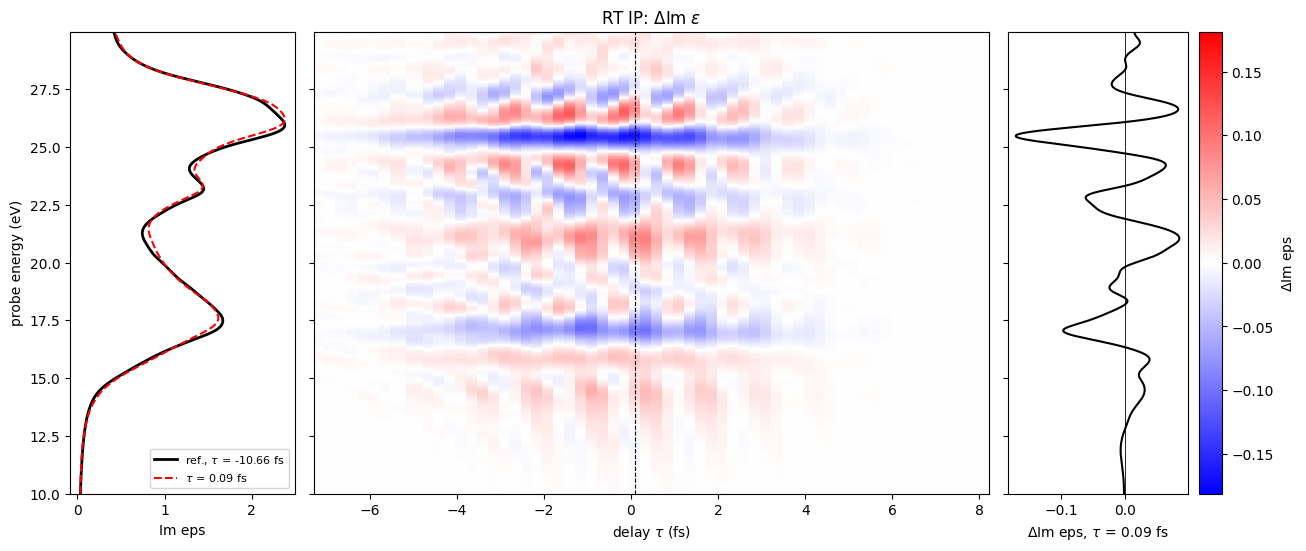

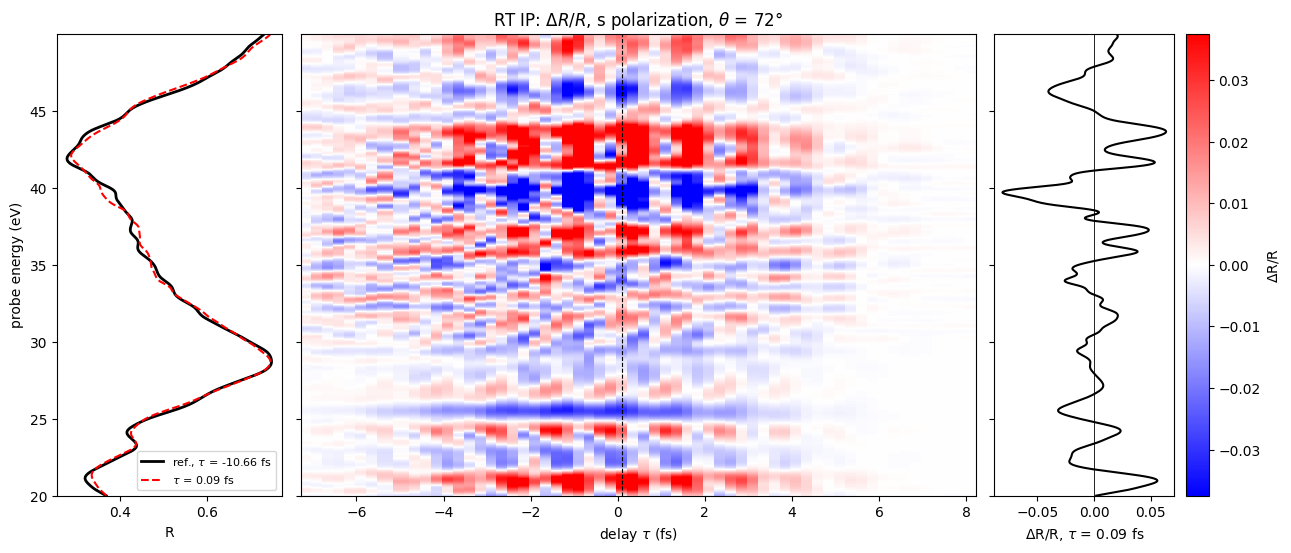

In [5]:
def plot_rt_map(runs, quantity='Im eps', relative=False, erange=(10,30), tau_cut=0., vmax=None, title=None, **kw):
    q = rt_quantity(runs,quantity,**kw)
    d = rt_quantity(runs,quantity,change=True,relative=relative,**kw)
    E, tau = runs['energy'], runs['tau']
    s = (E >= erange[0]) & (E <= erange[1])
    if vmax is None: vmax = np.abs(d[1:,s]).max()
    fig,axes = plt.subplots(1,3,figsize=(15,6),sharey=True,gridspec_kw=dict(width_ratios=[1,3,1],wspace=0.05))
    pc = axes[1].pcolormesh(tau[1:],E[s],d[1:,s].T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    lab = r'$\Delta$%s/%s'%(quantity,quantity) if relative else r'$\Delta$%s'%quantity
    fig.colorbar(pc,ax=axes[2],label=lab)
    i = np.argmin(np.abs(tau-tau_cut))
    axes[1].axvline(tau[i],color='k',lw=0.8,ls='--')
    axes[1].set_xlabel(r'delay $\tau$ (fs)')
    axes[1].set_title(title if title else lab)
    axes[0].plot(q[0,s],E[s],'k',lw=2,label=r'ref., $\tau$ = %.2f fs'%tau[0])
    axes[0].plot(q[i,s],E[s],'r--',label=r'$\tau$ = %.2f fs'%tau[i])
    axes[0].set_xlabel(quantity)
    axes[0].set_ylabel('probe energy (eV)')
    axes[0].legend(fontsize=8)
    axes[2].plot(d[i,s],E[s],'k')
    axes[2].axvline(0,color='k',lw=0.6)
    axes[2].set_xlabel(r'%s, $\tau$ = %.2f fs'%(lab,tau[i]))
    return fig,axes

plot_rt_map(rt_ip,'Im eps',title=r'RT IP: $\Delta$Im $\epsilon$')
plot_rt_map(rt_ip,'R',relative=True,theta=72,pol='s',erange=(20,50),vmax=0.0375,
            title=r'RT IP: $\Delta R/R$, s polarization, $\theta$ = 72°');

## Equilibrium susceptibilities (yambo_nl, kx16)

Damping 0.3 eV in the dynamics plus an a posteriori Lorentzian broadening of 0.3 eV (`compute_Xn(broadening=0.3)`, on
the keys linear in the probe): total 0.6 eV, the smoothing of the RT spectra.

In [6]:
run_dir = 'kx16_nb100_NoTr_E100'
name_sine = 'pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
name_Pp = 'Pp-Ep_1e3-EP_1e6-PE_1.55-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
data_sine = P.YamboNLDBParser(os.path.join(run_dir,name_sine,'ndb.Nonlinear'),verbose=False)
data_Pp = P.YamboNLDBParser(os.path.join(run_dir,name_Pp,'ndb.Nonlinear'),verbose=False)
freq_mix = O.Xn_frequency_mixing(data_Pp,X_order=(1,2),verbose=False)
broad = 0.3                            # eV, a posteriori broadening: 0.3 + 0.3 = 0.6 eV, the smoothing of the RT spectra
chi_freqmix = freq_mix.compute_Xn(broadening=broad)[0]
chi1_sin = O.Xn_single_frequency(data_sine,X_order=3,verbose=False).compute_Xn(broadening=broad)[0][1]
omega = freq_mix.probe_freqs           # Hartree
freqs = omega*Const.HaToeV
omega_P = freq_mix.pump_freq           # Hartree
EP = data_Pp.Efield2[0]['amplitude']   # au
x11m1 = (chi_freqmix[(1,0)] - chi1_sin)/(EP**2/4)
print('%d probe frequencies %.3f-%.3f eV, step/omega_P = %.4f, pump %.3f eV, E0 pump %.3e au'%(
      len(omega),freqs[0],freqs[-1],(omega[1]-omega[0])/omega_P,omega_P*Const.HaToeV,EP))

155 probe frequencies 10.000-24.919 eV, step/omega_P = 0.0625, pump 1.550 eV, E0 pump 1.194e-04 au


## Transient absorption from the non-linear $\chi$

The two descriptions are linked by the following equation
\begin{eqnarray}
\chi^{neq,(1)}[E_P](\omega) &=& \chi^{(1)}(\omega;\omega) + \nonumber \\
&+& \left[ \chi^{(2)}(\omega;\omega_P,\omega-\omega_P)\frac{E_{p}(\omega-\omega_P)}{E_p(\omega)} + 
\chi^{(2)}(\omega;-\omega_P,\omega+\omega_P)\frac{E_{p}(\omega+\omega_P)}{E_p(\omega)}
\right]E_{P}(\omega_P)  + \nonumber \\ &+&\left[   
\chi^{(3)}(\omega;\omega_P,\omega_P,\omega-2\omega_P)\frac{E_{p}(\omega-2\omega_P)}{E_p(\omega)} + 
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) + \right. \nonumber \\ &&\left.
\chi^{(3)}(\omega;-\omega_P,-\omega_P,\omega+2\omega_P)\frac{E_{p}(\omega+2\omega_P)}{E_p(\omega)}
\right]E^2_{P}(\omega_P)
\end{eqnarray}

### Formula used for $\delta\chi^{neq}$

The MPPI key `Xn_frequency_mixing(...).compute_Xn()[0][(1,m)]` at the probe frequency $\omega$ is the ratio between the
component of $P$ at $\omega+m\omega_P$ and the product $E_p(\omega)E_P(\pm\omega_P)^{|m|}$ of the field amplitudes, with
$E(t) = \sum_n E(\omega_n)e^{-i\omega_n t}$, $E(-\omega) = E(\omega)^*$, and $E(\omega) = (iE_0/2)e^{i\omega t_0}$ for a
sine field $E_0\sin(\omega(t-t_0))$ (Boyd, Sec. 1.3; the keys include the degeneracy factors, $\chi_{(1,\pm2)} = 3\chi^{(3)}$).

Only the third order terms are kept: the second order terms $\chi_{(1,\pm1)}$ vanish by symmetry in LiF (in our runs
they are an error of the k discretization, see `NL-Chi_Analysis.ipynb`). The change of the response at the frequency
$\omega$ of the transient spectrum is

$$
\delta\chi(\omega) = \chi_{(1,1,-1)}(\omega)|E_P(\omega_P)|^2
+ \chi_{(1,2)}(\omega-2\omega_P)\frac{E_p(\omega-2\omega_P)}{E_p(\omega)}E_P(\omega_P)^2
+ \chi_{(1,-2)}(\omega+2\omega_P)\frac{E_p(\omega+2\omega_P)}{E_p(\omega)}E_P(-\omega_P)^2 ,
\qquad \chi_{(1,1,-1)} = \frac{\chi_{(1,0)}-\chi^{(1)}}{E_{0P,run}^2/4}
$$

($E_{0P,run}$ is the pump amplitude of the yambo_nl run). It holds for a monochromatic pump. The fields of the RT runs:

- **probe**: delta kick at $t_p$, $E_p(\omega)\propto e^{i\omega t_p}$, so $E_p(\omega\mp2\omega_P)/E_p(\omega) =
  e^{\mp2i\omega_P t_p}$;
- **pump**: a pulse. For QSFIELD with phase 90° yambo (`RT_small_a`) sets the vector potential
  $A(t)\propto f(t)\cos(\omega_P(t-t_P))$, with the envelope $f(t) = e^{-(t-t_P)^2/2\sigma^2}$ centered at $t_P$, and
  $E = -\dot A$. Neglecting the derivative of the envelope ($\sigma$ = 3.2 fs $\gg 1/\omega_P$ = 0.42 fs):
  $E_P(t) = -E_{0P}f(t)\sin(\omega_P(t-t_P))$.

**Quasi-monochromatic approximation.** The signal of the delta probe is built in a short time after $t_p$: the
smoothing of 0.6 eV damps the probe polarization in $\hbar/0.6$ eV $\simeq$ 1.1 fs, shorter than $\sigma$. In this
time the envelope is nearly constant, $f(t)\simeq f(t_p) = e^{-\tau^2/2\sigma^2}$ with the delay $\tau = t_p - t_P$, so
the pump acts on the probe response as a monochromatic sine field of amplitude $E_{0P}f(\tau)$ with phase reference
$t_P$. With the convention above its amplitude is $E_P(\omega_P) = -(iE_{0P}f(\tau)/2)\,e^{i\omega_P t_P}$, hence

$$
|E_P(\omega_P)|^2 = \frac{E_{0P}^2}{4}e^{-\tau^2/\sigma^2} \equiv |E_P(\tau)|^2, \qquad
E_P(\pm\omega_P)^2 = -|E_P(\tau)|^2\,e^{\pm2i\omega_P t_P} .
$$

The minus sign is the square of $i$, i.e. it comes from the sine shape of the pump (for a cosine pump it would be +);
the global sign of the field does not matter. Combining the phases of the probe and of the pump,
$e^{\mp2i\omega_P(t_p-t_P)} = e^{\mp2i\omega_P\tau}$:

$$
\delta\chi(\omega,\tau) = |E_P(\tau)|^2\left[\chi_{(1,1,-1)}(\omega) - \chi_{(1,2)}(\omega-2\omega_P)\,e^{-2i\omega_P\tau}
- \chi_{(1,-2)}(\omega+2\omega_P)\,e^{2i\omega_P\tau}\right]
$$

and $\Delta\epsilon(\omega,\tau) = 4\pi\,\delta\chi(\omega,\tau)$ is compared with $\epsilon(\omega,\tau)-\epsilon_{ref}(\omega)$
of the RT runs. The phases depend only on the delay: the term $\chi_{(1,1,-1)}$ does not oscillate with $\tau$, the
$(1,\pm2)$ terms oscillate with period $\pi/\omega_P$ = 1.33 fs.

### Frequency grids

The key $(1,m)$ computed at the probe frequency $\omega'$ of the runs is the response at $\omega'+m\omega_P$. In the
spectrum at the frequency $\omega$ the three terms are therefore read at $\omega' = \omega$ ($\chi_{(1,1,-1)}$),
$\omega-2\omega_P$ ($\chi_{(1,2)}$) and $\omega+2\omega_P$ ($\chi_{(1,-2)}$). Each key alone covers a shifted range of
output frequencies, but $\delta\chi(\omega)$ is defined only where all three terms are available:
$\omega\in[\omega'_{min}+2\omega_P,\ \omega'_{max}-2\omega_P]$ = 13.10-21.82 eV for the probe window 10.000-24.919 eV.
The probe step of the runs is $\omega_P/16$ = 0.096875 eV, so $2\omega_P$ = 32 steps and the shifted frequencies are
exactly on the grid (an index shift, no interpolation). A wider range of $\omega$ needs a wider probe window.

Other ingredients of the comparison with the RT runs:

- **pump frequency**: 1.55 eV in the yambo_nl runs, 1.56 eV in the RT runs. The keys are read with the shift $2\omega_P$
  of the runs (3.10 instead of 3.12 eV, negligible with a broadening of 0.6 eV), the phases $e^{\mp2i\omega_P\tau}$ use
  the RT pump frequency (0.02 eV give 0.4 rad at 7 fs);
- **pump amplitude**: yambo intensities are in kW/cm$^2$ (the `kWLm2` of the inputs; $E_0 = \sqrt{4\pi I/c}$ in atomic
  units, 1e6 kW/cm$^2$ give the $E_0$ = 1.194e-4 au of our runs). The RT pump, 6e9 kW/cm$^2$, has $E_{0P}$ = 9.25e-3 au:
  intensity 6000 times the one of our runs, far beyond the range of the pump intensity test (fifth order corrections
  $\propto I_P$, 1-2% of the cubic terms at 1.6e7 kW/cm$^2$), so higher orders can be relevant in the RT runs;
- **bands**: 3-6 in our runs, 1-15 in the RT IP runs: transitions to the bands above 6 (from $\sim$19-20 eV) are missing
  in our $\chi$.

In [7]:
def dchi_neq(freqs, chi, chi1, EP_run, taus, E0P, sigma=None, wP=None, wP_phase=None):
    '''
    Pump induced change of the probe response (third order terms, MPPI keys), for a delta probe and a sine pump:
        dchi(w,tau) = |E_P(tau)|^2 [x3(w) - chi_(1,2)(w-2wP) exp(-2i wP tau) - chi_(1,-2)(w+2wP) exp(2i wP tau)]
    with x3 = (chi_(1,0)-chi1)/(EP_run^2/4) and |E_P(tau)|^2 = E0P^2/4 exp(-tau^2/sigma^2).

    Args:
        freqs : probe frequencies of the runs (eV), uniform grid with 2 wP equal to a multiple of the step
        chi : keys of Xn_frequency_mixing.compute_Xn on the grid freqs ((1,0), (1,2), (1,-2))
        chi1 : linear response on the grid freqs (e.g. first harmonic of the sine runs)
        EP_run : pump amplitude E0 of the yambo_nl run (au)
        taus : delays probe - pump maximum (fs)
        E0P : pump amplitude E0 to be used (au)
        sigma : width of the gaussian envelope of the pump field (fs), None for a monochromatic pump
        wP : pump frequency of the runs (eV), it fixes the shifted grids
        wP_phase : pump frequency (eV) in the phases exp(-+2i wP tau), default wP

    Returns:
        w (eV) : frequencies of the spectrum, freqs[n:-n] with n = 2wP/step
        dchi : array (len(taus), len(w)) in au (Delta eps = 4 pi dchi)
    '''
    if wP_phase is None: wP_phase = wP
    step = freqs[1]-freqs[0]
    n = int(round(2*wP/step))
    assert abs(n*step-2*wP) < 1e-3*step, '2 wP is not a multiple of the frequency step'
    taus = np.atleast_1d(taus)[:,None]
    x3 = (chi[(1,0)]-chi1)/(EP_run**2/4)
    phase = 2*wP_phase/Const.Planck_reduced_ev_fs*taus
    env2 = 1. if sigma is None else np.exp(-(taus/sigma)**2)
    dchi = E0P**2/4*env2*(x3[n:-n] - chi[(1,2)][:-2*n]*np.exp(-1j*phase) - chi[(1,-2)][2*n:]*np.exp(1j*phase))
    return freqs[n:-n], dchi

# pump of the RT runs: amplitude from the ratio of the intensities (kW/cm^2) w.r.t. the yambo_nl run (1e6 kW/cm^2)
pump_rt = rt_ip['pump']
E0P_rt = EP*np.sqrt(pump_rt['intensity']/1e6)
w, dchi = dchi_neq(freqs,chi_freqmix,chi1_sin,EP,rt_ip['tau'],E0P_rt,sigma=pump_rt['sigma'],
                   wP=omega_P*Const.HaToeV,wP_phase=pump_rt['freq'])
deps_chi = 4*np.pi*dchi
deps_rt = np.array([np.interp(w,rt_ip['energy'],d.real)+1j*np.interp(w,rt_ip['energy'],d.imag)
                    for d in rt_ip['eps']-rt_ip['eps'][0]])
print('omega %.3f-%.3f eV (%d points), E0P of the RT pump %.3e au (%.0f times the yambo_nl one)'%(w[0],w[-1],len(w),E0P_rt,E0P_rt/EP))

omega 13.100-21.819 eV (91 points), E0P of the RT pump 9.246e-03 au (77 times the yambo_nl one)


Comparison at three delays around the pump maximum (black: RT, red: from the $\chi$) and maps of $\Delta$Im $\epsilon$
vs the delay (same color scale).

RT    max |Delta eps| (all delays): 13.1-17.5 eV 0.107, 17.5-21.8 eV 0.099
chi3  max |Delta eps| (all delays): 13.1-17.5 eV 0.155, 17.5-21.8 eV 0.093


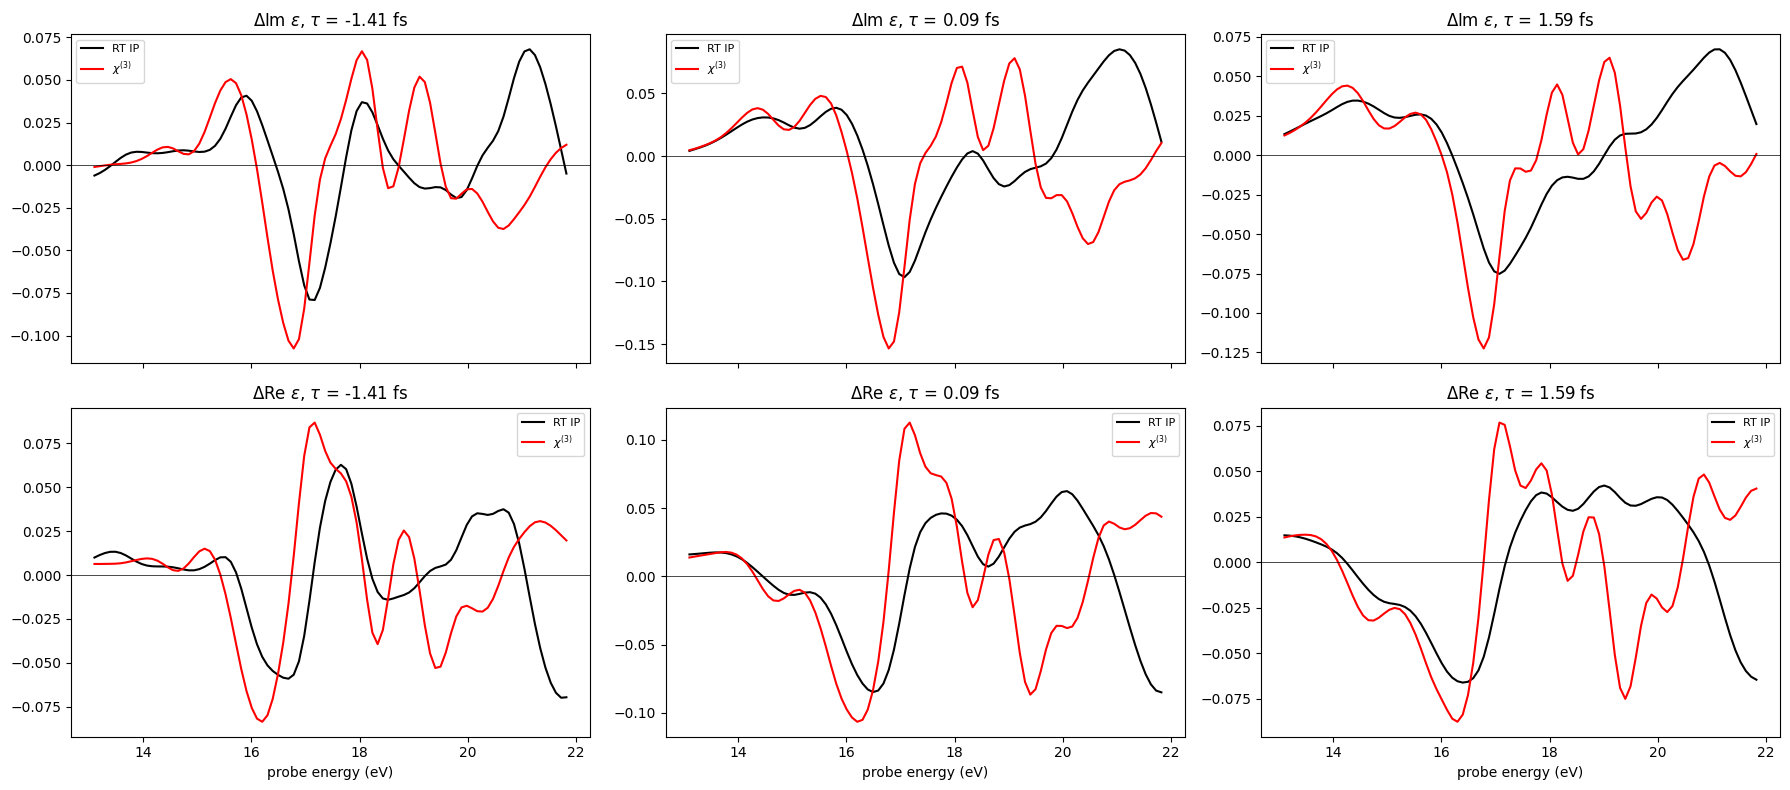

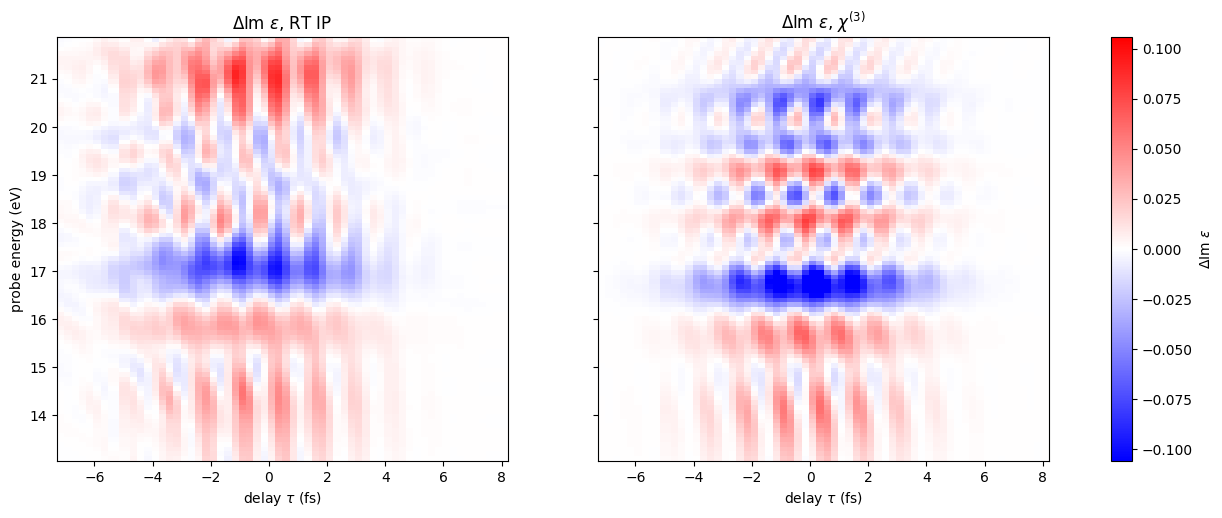

In [8]:
taus_cmp = [-1.4,0.1,1.6]
fig,axes = plt.subplots(2,len(taus_cmp),figsize=(18,8),sharex=True)
for k,t in enumerate(taus_cmp):
    i = np.argmin(np.abs(rt_ip['tau']-t))
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(deps_rt[i]),'k',label='RT IP')
        ax.plot(w,part(deps_chi[i]),'r',label=r'$\chi^{(3)}$')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,rt_ip['tau'][i]))
        ax.legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

it = np.arange(1,len(rt_ip['tau']))
vmax = np.abs(deps_rt[it].imag).max()
fig,axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True)
for ax,d,lab in zip(axes,[deps_rt,deps_chi],['RT IP',r'$\chi^{(3)}$']):
    pc = ax.pcolormesh(rt_ip['tau'][it],w,d[it].imag.T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    ax.set_title(r'$\Delta$Im $\epsilon$, %s'%lab)
    ax.set_xlabel(r'delay $\tau$ (fs)')
axes[0].set_ylabel('probe energy (eV)')
fig.colorbar(pc,ax=axes,label=r'$\Delta$Im $\epsilon$')

m = w < 17.5
for lab,d in [('RT',deps_rt),('chi3',deps_chi)]:
    print('%-5s max |Delta eps| (all delays): 13.1-17.5 eV %.3f, 17.5-21.8 eV %.3f'%(lab,np.abs(d[it][:,m]).max(),np.abs(d[it][:,~m]).max()))

**First comparison (RT IP vs $\chi^{(3)}$, no free parameters).** Below $\sim$17.5 eV the reconstruction from the
$\chi$ reproduces the RT spectra: the bleach at 17 eV, the positive band at 14-16 eV, the oscillations with period
$\pi/\omega_P$ = 1.33 fs in phase with the RT ones and the decay with the pump envelope. The bleach at 17 eV is
$\sim$1.5 times larger than in the RT runs (see the maxima printed above). Above 17.5 eV the shapes differ. Possible
causes, to be checked: higher orders at the RT pump intensity (6000 times the one of our runs), the k convergence of the
cubic terms in 16-21 eV (not converged at kx16), the bands above 6 missing in our runs.